<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   row_id               9800 non-null   int64         
 1   order_id             9800 non-null   str           
 2   order_date           9800 non-null   datetime64[us]
 3   ship_date            9800 non-null   datetime64[us]
 4   ship_mode            9800 non-null   str           
 5   customer_id          9800 non-null   str           
 6   customer_name        9800 non-null   str           
 7   segment              9800 non-null   str           
 8   country              9800 non-null   str           
 9   city                 9800 non-null   str           
 10  state                9800 non-null   str           
 11  postal_code          9800 non-null   str           
 12  region               9800 non-null   str           
 13  product_id           9800 non-null   str    

,row_id,order_date,ship_date,sales,days_to_ship
count,9800.000000,9800,9800,9800.000000,9800.000000
mean,4900.500000,2017-05-01 05:13:51.673469,2017-05-05 04:17:52.653061,230.769059,3.961122
min,1.000000,2015-01-03 00:00:00,2015-01-07 00:00:00,0.444000,0.000000
25%,2450.750000,2016-05-24 00:00:00,2016-05-27 18:00:00,17.248000,3.000000
50%,4900.500000,2017-06-26 00:00:00,2017-06-29 00:00:00,54.490000,4.000000
75%,7350.250000,2018-05-15 00:00:00,2018-05-19 00:00:00,210.605000,5.000000
max,9800.000000,2018-12-30 00:00:00,2019-01-05 00:00:00,22638.480000,7.000000
std,2829.160653,NaN,NaN,626.651875,1.749614


row_id                 0
order_id               0
order_date             0
ship_date              0
ship_mode              0
customer_id            0
customer_name          0
segment                0
country                0
city                   0
state                  0
postal_code            0
region                 0
product_id             0
category               0
sub_category           0
product_name           0
sales                  0
postal_code_imputed    0
possible_duplicate     0
product_id_conflict    0
sales_outlier          0
days_to_ship           0
dtype: int64

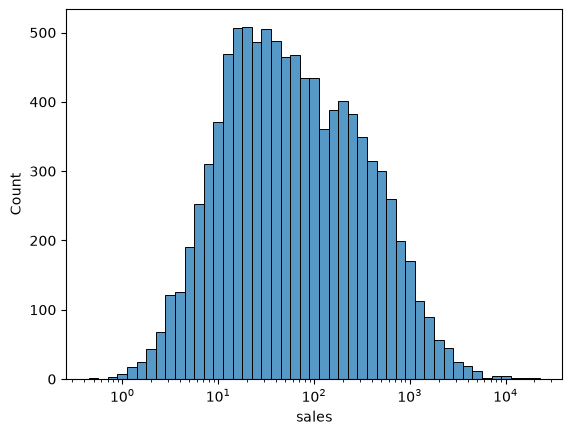

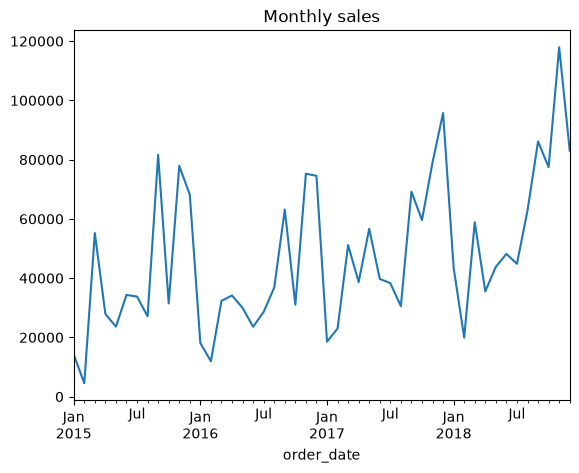

region,Central,East,South,West
category,,,,
Furniture,160317.0,206461.0,116531.0,245348.0
Office Supplies,163590.0,199941.0,124425.0,217467.0
Technology,168739.0,263117.0,148195.0,247405.0


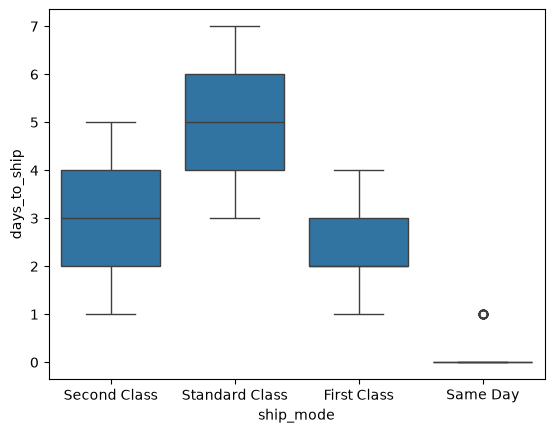

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\Retail Sales Analysis\data\train_clean.csv", parse_dates=["order_date", "ship_date"],
                 dtype={"postal_code": str})

# Structure and quality
df.info()
display(df.describe())
display(df.isna().sum())

# Distribution of sales (log scale because it is heavily skewed)
# The average sale is about $231 but the median is only about $54, so a few large orders pull the average up.
sns.histplot(df.sales, log_scale=True)
plt.show()

# Monthly trend
df.resample("MS", on="order_date").sales.sum().plot(title="Monthly sales")
plt.show()

# Category and region
display(df.pivot_table(index="category", columns="region",
                       values="sales", aggfunc="sum").round(0))

# Shipping time by ship mode
sns.boxplot(data=df, x="ship_mode", y="days_to_ship")
plt.show()